<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-2-MLP-Backpropagation/fashion_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10 | Loss: 1.7252 | Train Accuracy: 64.33% | Test Accuracy: 63.05%
Epoch 2/10 | Loss: 1.1049 | Train Accuracy: 69.11% | Test Accuracy: 67.30%
Epoch 3/10 | Loss: 0.9057 | Train Accuracy: 69.97% | Test Accuracy: 68.35%
Epoch 4/10 | Loss: 0.8090 | Train Accuracy: 73.39% | Test Accuracy: 72.05%
Epoch 5/10 | Loss: 0.7471 | Train Accuracy: 76.28% | Test Accuracy: 75.40%
Epoch 6/10 | Loss: 0.7028 | Train Accuracy: 77.19% | Test Accuracy: 76.00%
Epoch 7/10 | Loss: 0.6672 | Train Accuracy: 74.14% | Test Accuracy: 73.40%
Epoch 8/10 | Loss: 0.6427 | Train Accuracy: 78.27% | Test Accuracy: 77.10%
Epoch 9/10 | Loss: 0.6182 | Train Accuracy: 77.58% | Test Accuracy: 76.35%
Epoch 10/10 | Loss: 0.5973 | Train Accuracy: 79.73% | Test Accuracy: 78.95%

Final Test Accuracy: 78.95 %


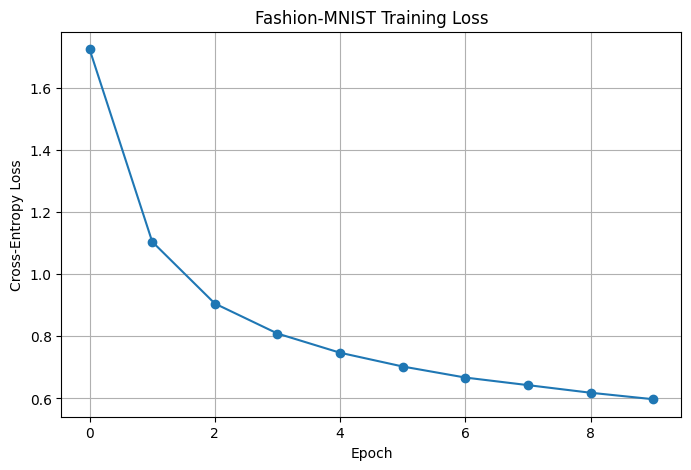

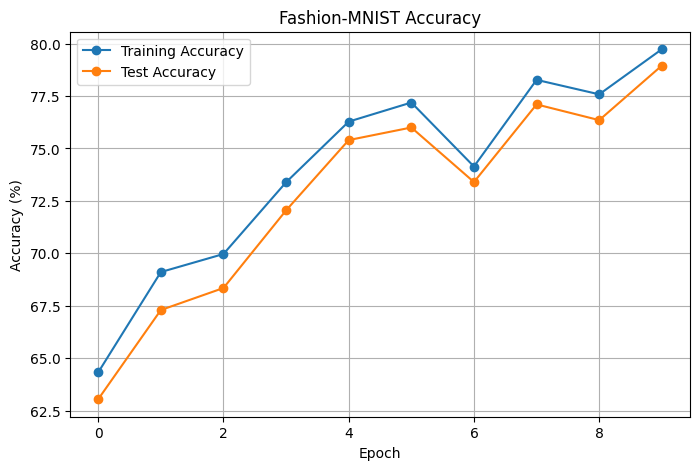

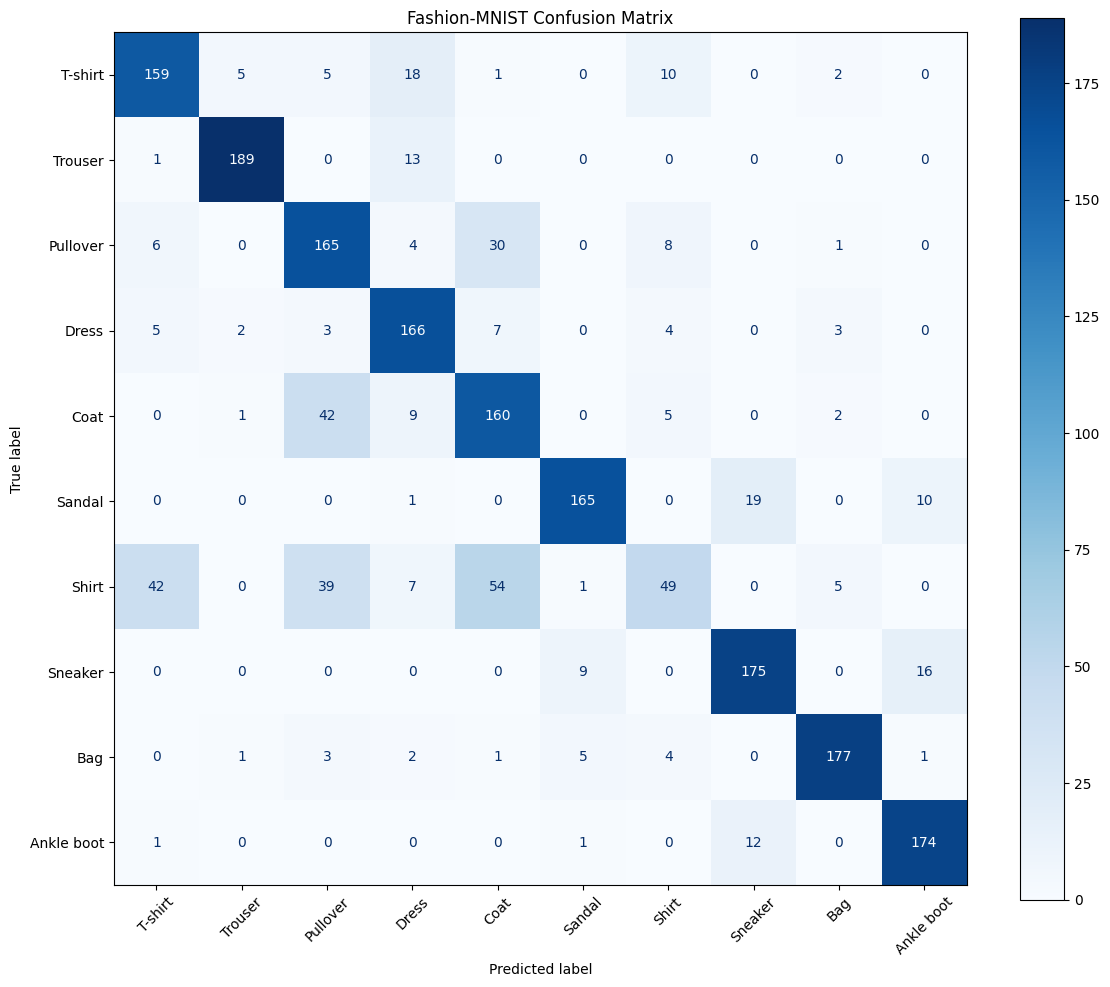


Classification Report:
              precision    recall  f1-score   support

     T-shirt       0.74      0.80      0.77       200
     Trouser       0.95      0.93      0.94       203
    Pullover       0.64      0.77      0.70       214
       Dress       0.75      0.87      0.81       190
        Coat       0.63      0.73      0.68       219
      Sandal       0.91      0.85      0.88       195
       Shirt       0.61      0.25      0.35       197
     Sneaker       0.85      0.88      0.86       200
         Bag       0.93      0.91      0.92       194
  Ankle boot       0.87      0.93      0.89       188

    accuracy                           0.79      2000
   macro avg       0.79      0.79      0.78      2000
weighted avg       0.79      0.79      0.78      2000



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1. Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Use a subset to make training faster
X_train = X_train[:10000]
y_train = y_train[:10000]

X_test = X_test[:2000]
y_test = y_test[:2000]

# 2. Preprocess images
X_train = X_train.reshape(-1, 784).astype(np.float32) / 255.0
X_test = X_test.reshape(-1, 784).astype(np.float32) / 255.0

# One-hot encoding
num_classes = 10

Y_train = np.eye(num_classes)[y_train]
Y_test = np.eye(num_classes)[y_test]

# 3. Define activation functions
def relu(x):
    return np.maximum(0, x)

def softmax(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# 4. Initialize weights using He initialization
np.random.seed(42)

W1 = np.random.randn(784, 128) * np.sqrt(2 / 784)
b1 = np.zeros((1, 128))

W2 = np.random.randn(128, 64) * np.sqrt(2 / 128)
b2 = np.zeros((1, 64))

W3 = np.random.randn(64, 10) * np.sqrt(2 / 64)
b3 = np.zeros((1, 10))

# 5. Training settings
learning_rate = 0.01
epochs = 10
batch_size = 128

train_losses = []
train_accuracies = []
test_accuracies = []

# 6. Train the NumPy MLP
for epoch in range(epochs):

    indices = np.random.permutation(len(X_train))
    X_shuffled = X_train[indices]
    Y_shuffled = Y_train[indices]

    epoch_loss = 0

    for start in range(0, len(X_train), batch_size):

        end = start + batch_size

        xb = X_shuffled[start:end]
        yb = Y_shuffled[start:end]

        m = len(xb)

        # FORWARD PROPAGATION
        Z1 = xb @ W1 + b1
        A1 = relu(Z1)

        Z2 = A1 @ W2 + b2
        A2 = relu(Z2)

        Z3 = A2 @ W3 + b3
        A3 = softmax(Z3)

        # Cross-entropy loss
        epsilon = 1e-8
        loss = -np.mean(
            np.sum(yb * np.log(A3 + epsilon), axis=1)
        )

        epoch_loss += loss * m

        # BACKPROPAGATION
        dZ3 = (A3 - yb) / m

        dW3 = A2.T @ dZ3
        db3 = np.sum(dZ3, axis=0, keepdims=True)

        dA2 = dZ3 @ W3.T
        dZ2 = dA2 * (Z2 > 0)

        dW2 = A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ W2.T
        dZ1 = dA1 * (Z1 > 0)

        dW1 = xb.T @ dZ1
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        # UPDATE WEIGHTS
        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

    # Average training loss
    epoch_loss /= len(X_train)
    train_losses.append(epoch_loss)

    # Calculate training accuracy
    _, _, _, _, _, train_probs = forward = (
        X_train @ W1 + b1,
        None, None, None, None, None
    )

    # Forward prediction on training and test data
    def predict_proba(X):
        a1 = relu(X @ W1 + b1)
        a2 = relu(a1 @ W2 + b2)
        return softmax(a2 @ W3 + b3)

    train_predictions = np.argmax(
        predict_proba(X_train), axis=1
    )

    test_predictions = np.argmax(
        predict_proba(X_test), axis=1
    )

    train_accuracy = np.mean(
        train_predictions == y_train
    ) * 100

    test_accuracy = np.mean(
        test_predictions == y_test
    ) * 100

    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

# 7. Final evaluation
final_predictions = np.argmax(
    predict_proba(X_test), axis=1
)

final_accuracy = np.mean(
    final_predictions == y_test
) * 100

print("\nFinal Test Accuracy:", round(final_accuracy, 2), "%")

# 8. Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, marker="o")
plt.title("Fashion-MNIST Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()

# 9. Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, marker="o", label="Training Accuracy")
plt.plot(test_accuracies, marker="o", label="Test Accuracy")
plt.title("Fashion-MNIST Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

# 10. Confusion matrix
class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

cm = confusion_matrix(y_test, final_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues")
plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

# 11. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=class_names
))

##Observations and Conclusion

Observations

1. Fashion-MNIST contains 10 different clothing categories.
2. Images are converted into 784 numerical input features.
3. The MLP uses two hidden layers with 128 and 64 neurons.
4. ReLU activation is used in hidden layers.
5. Softmax is used in the output layer.
6. He initialization is used for weight initialization.
7. Cross-entropy loss measures classification error.
8. Backpropagation updates network weights.
9. The confusion matrix shows correct and incorrect classifications.

Conclusion

A Multilayer Perceptron implemented using NumPy can perform multiclass classification on Fashion-MNIST. The experiment demonstrates forward propagation, backpropagation, weight initialization, and neural network evaluation.